<a href="https://colab.research.google.com/github/Aishalwalay/COU07506-labs/blob/main/COU07506_Week01_240242465086.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
import numpy as np
import matplotlib.pyplot as plt

In [22]:
n = np.arange(-5, 11)

delta = (n == 0).astype(float)
step = (n >= 0).astype(float)
ramp = n * step
expo = 0.8**n * step

In [23]:
n = np.arange(-5, 11)

delta = (n == 0).astype(float)
step = (n >= 0).astype(float)
ramp = n * step
expo = 0.8**n * step

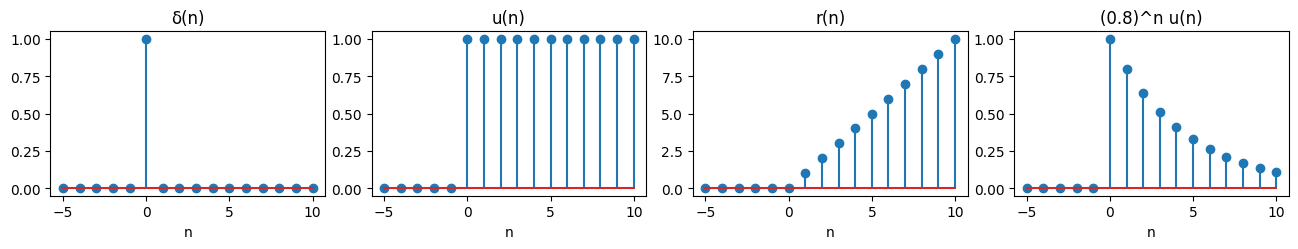

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))

for ax, x, title in zip(
    axes,
    [delta, step, ramp, expo],
    ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]
):
    ax.stem(n, x)
    ax.set_title(title)
    ax.set_xlabel("n")

plt.tight_layout()
plt.show()

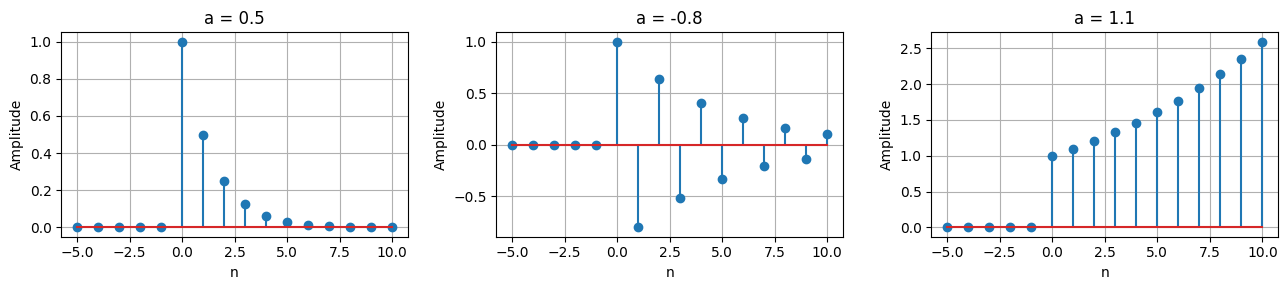

In [25]:
a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3))

for ax, a in zip(axes, a_values):

    x = (a**n) * step

    ax.stem(n, x)
    ax.set_title(f"a = {a}")
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")
    ax.grid()

plt.tight_layout()
plt.show()

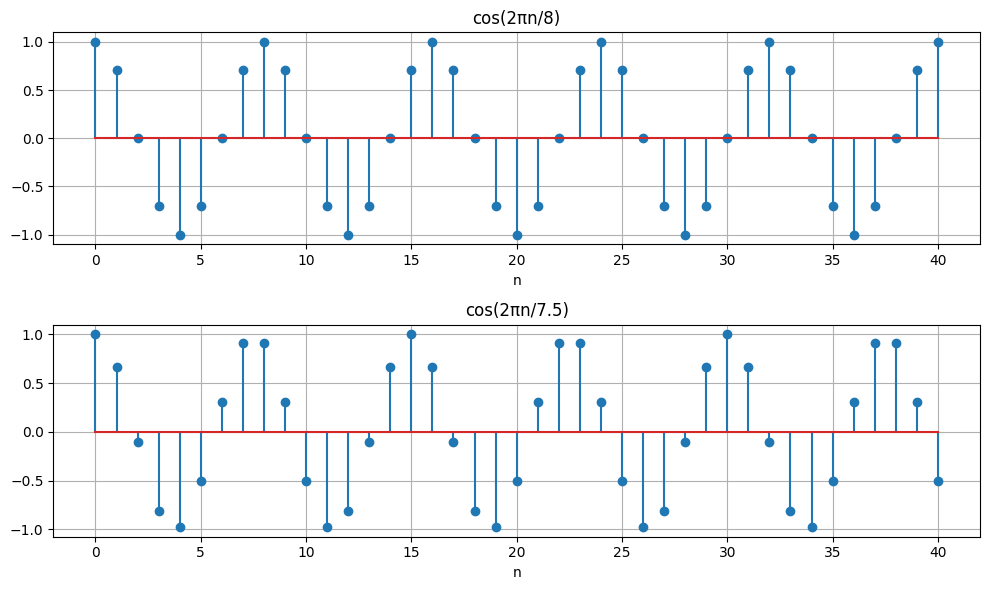

In [26]:
n2 = np.arange(0, 41)

x1 = np.cos(2*np.pi*n2/8)
x2 = np.cos(2*np.pi*n2/7.5)

fig, axes = plt.subplots(2, 1, figsize=(10, 6))

axes[0].stem(n2, x1)
axes[0].set_title("cos(2πn/8)")
axes[0].set_xlabel("n")
axes[0].grid()

axes[1].stem(n2, x2)
axes[1].set_title("cos(2πn/7.5)")
axes[1].set_xlabel("n")
axes[1].grid()

plt.tight_layout()
plt.show()

In [27]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile

fname = "my_voice.wav"

if os.path.exists(fname):
    fs, x = wavfile.read(fname)

    if x.ndim > 1:
        x = x.mean(axis=1)

    x = x / np.max(np.abs(x))

else:
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)

Sampling rate: 16000 Hz
Duration: 2.00 seconds
Samples: 32000


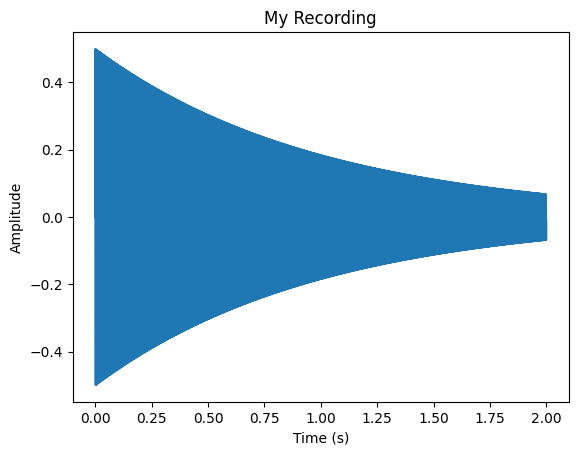

In [28]:
t = np.arange(0, len(x))/fs

print(f"Sampling rate: {fs} Hz")
print(f"Duration: {len(x)/fs:.2f} seconds")
print(f"Samples: {len(x)}")

plt.plot(t, x)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("My Recording")
plt.show()

In [29]:
import os

print(os.listdir("/content"))

['.config', 'my voice.wav', 'sample_data']


In [30]:
fname = "/content/my voice.wav"

In [31]:
import librosa
from IPython.display import Audio, display

# Load your voice file
y, sr = librosa.load('/content/my voice.wav', sr=None)

# Play your original voice
display(Audio(y, rate=sr))

Files found: ['my voice.wav']
Using file: my voice.wav
fs = 44100 Hz, duration = 4.08 s, samples = 179906


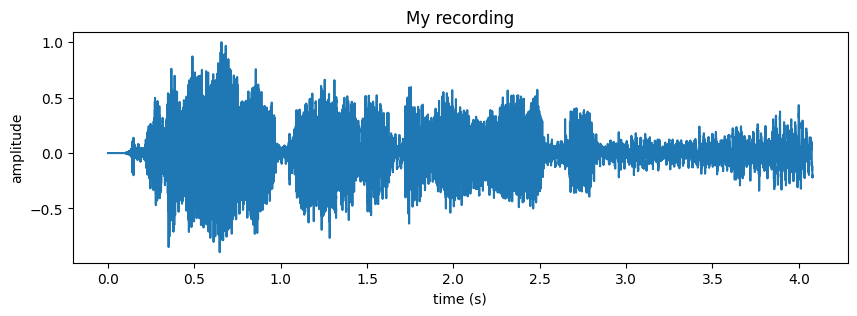

In [32]:
import os, glob, subprocess
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from IPython.display import Audio, display


found = [f for f in glob.glob("*") if "voice" in f.lower()]
print("Files found:", found)
fname = found[0] if found else None


if fname and not fname.lower().endswith(".wav"):
    subprocess.run(["ffmpeg", "-y", "-i", fname, "my_voice.wav"],
                   stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    fname = "my_voice.wav"


if fname and os.path.exists(fname):
    print("Using file:", fname)
    fs, x = wavfile.read(fname)
    x = x.astype(float)
    if x.ndim > 1:
        x = x.mean(axis=1)              # stereo -> mono
    x = x / np.max(np.abs(x))           # normalise to [-1, 1]
else:
    print("File NOT found, using 440 Hz test signal")
    fs = 16000
    t0 = np.arange(0, 2, 1/fs)
    x = 0.5 * np.sin(2*np.pi*440*t0) * np.exp(-t0)


t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")

plt.figure(figsize=(10, 3))
plt.plot(t, x)
plt.xlabel("time (s)")
plt.ylabel("amplitude")
plt.title("My recording")
plt.show()


display(Audio(x, rate=fs))